In [1]:
import os
import cv2
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import matplotlib.patches as mpatches

from mapping import stenosis_colors_rgb

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
path2metaframe = "./data/metaframe.csv"
frame = pd.read_csv(path2metaframe)
print(frame.shape)

(8291, 13)


In [3]:
# Количество боксов как в описании датасета
frame.groupby('cls').size()

cls
-         2130
p0_20     1944
p100       204
p20_50    1128
p50_70     999
p70_90     893
p90_98     930
p99         63
dtype: int64

### Случайная визуализация нескольких фреймов

In [4]:
sub_gr = frame.groupby("frame").size()
sub_gr[sub_gr > 5]

frame
p24_v4_00027    6
p24_v4_00028    6
p24_v4_00029    6
p24_v4_00034    6
p24_v4_00035    6
p24_v4_00036    6
p24_v4_00037    6
p24_v4_00038    6
p24_v4_00039    6
p24_v4_00040    6
p24_v4_00041    6
p24_v4_00042    6
p24_v4_00043    6
p24_v4_00044    6
p24_v4_00045    6
p24_v4_00046    6
p24_v4_00047    6
p24_v4_00048    6
p24_v4_00049    6
p24_v4_00050    6
p24_v4_00051    6
p24_v4_00052    6
p24_v5_00035    6
p24_v5_00037    6
p24_v5_00038    6
p24_v5_00039    6
p24_v5_00040    6
dtype: int64

In [22]:
num_frames = 50

frames_names = frame['frame'].unique().tolist()
select_frames = np.random.choice(frames_names, size=num_frames)

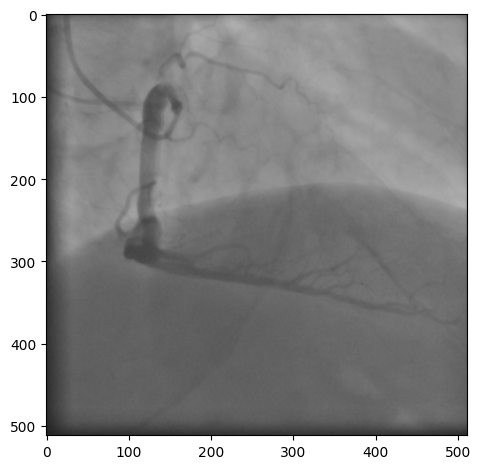

In [23]:
for idx, i_frame in enumerate(select_frames):
    # --- select sub frame ---
    sub_frame = frame[frame['frame'] == i_frame].reset_index()

    # --- read img ---
    img = cv2.imread(sub_frame.loc[0, 'path2frame'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    break

plt.imshow(img_rgb)
plt.tight_layout()
plt.show()

(x, y) - левый верхний угол
w, h - ширина и высота, соответственно

TypeError: 'Axes' object is not subscriptable

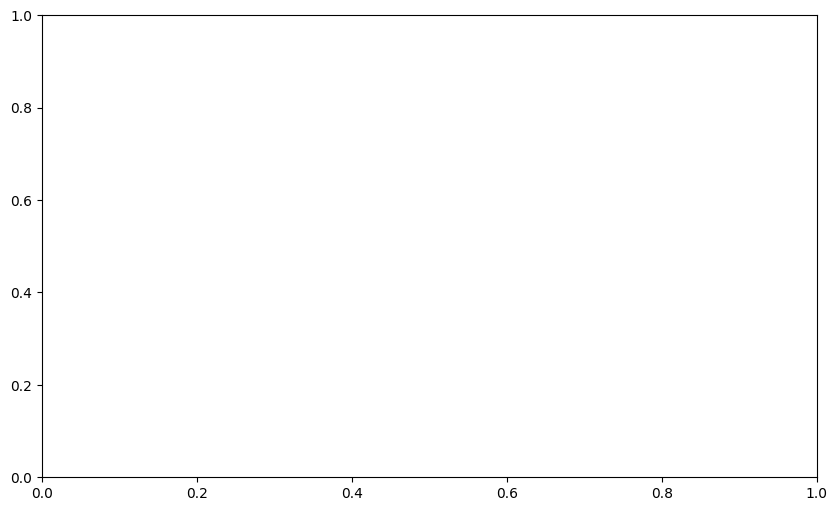

In [9]:
fig, axs = plt.subplots(num_frames, 1, figsize=(10, 6 * num_frames))

for idx, i_frame in enumerate(select_frames):
    # --- select sub frame ---
    sub_frame = frame[frame['frame'] == i_frame].reset_index()

    # --- read img ---
    img = cv2.imread(sub_frame.loc[0, 'path2frame'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- add bboxes ---
    legends = {}
    for i, irow in sub_frame.iterrows():
        icls = irow['cls'] 
        
        if icls == '-': # if nonlesion frame
            break

        x = int(irow['x'])
        y = int(irow['y']) 
        w = int(irow['w']) 
        h = int(irow['h']) 
        pt1 = (x, y)
        pt2 = (x + w, y + h)
        icolor = stenosis_colors_rgb[icls]

        if icls not in legends:
            legends[icls] = mpatches.Patch(color=tuple(item/255.0 for item in icolor), label=icls)

        cv2.rectangle(img_rgb, pt1, pt2, color=icolor, thickness=2)


    # --- add legend ---
    legend_handles = [legends[item] for item in legends]
    axs[idx].legend(handles=legend_handles, loc="upper right", framealpha=0.8)

    # --- print img ---
    axs[idx].imshow(img_rgb)
    axs[idx].set_title(f"{i_frame}")

plt.tight_layout()
plt.show()

In [63]:
sub_frames = frame[frame['cls'] == 'p99'].reset_index()

In [64]:
frames = sub_frames['frame'].unique().tolist()

In [65]:
item = frames[-1]
sub_frame = sub_frames[sub_frames['frame'] == item]

img_path = sub_frame.iloc[0]['path2frame']
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# --- add bboxes ---
legends = {}
for i, irow in sub_frame.iterrows():
    icls = irow['cls'] 
    
    if icls == '-': # if nonlesion frame
        break

    x = int(irow['x'])
    y = int(irow['y']) 
    w = int(irow['w']) 
    h = int(irow['h']) 
    pt1 = (x, y)
    pt2 = (x + w, y + h)
    icolor = stenosis_colors_rgb[icls]

    if icls not in legends:
        legends[icls] = mpatches.Patch(color=tuple(item/255.0 for item in icolor), label=icls)

    cv2.rectangle(img_rgb, pt1, pt2, color=icolor, thickness=2)

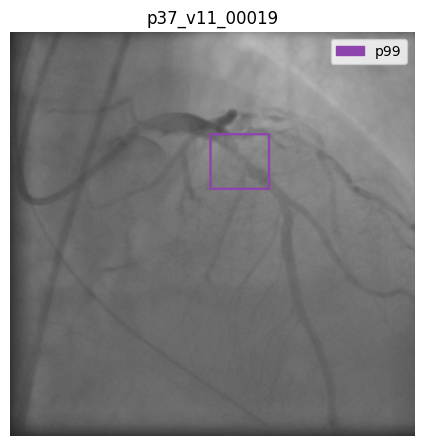

In [66]:
# --- add legend ---
legend_handles = [legends[item] for item in legends]
plt.legend(handles=legend_handles, loc="upper right", framealpha=0.8)
plt.imshow(img_rgb)
plt.title(item)
plt.tight_layout()
plt.axis(False)
plt.show()